# Breast Cancer Wisconsin (scikit-learn): clustering

569 tumours, 30 cell-nucleus measurements (scikit-learn copy of the UCI table), standardized. Benign / malignant are the reference labels (report dataset D7).

Every method is tuned by the shared, label-free rule (`sc4020.tuning`); labels are used only for the
external scores. Sections: dataset loading, one section per method, metrics, visualization. Tables go to
`results/datasets/breast_cancer_results.csv` and `breast_cancer_tuning.csv`, figures to `results/datasets/figures/`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sc4020 import run, tuning
from sc4020.datasets import load_dataset
from sc4020.paths import REPORT_FIGURES_DIR

warnings.filterwarnings("ignore")
np.random.seed(run.SEED)

DATASET_NAME = "breast_cancer"
TOPIC = "datasets"
MAX_CLUSTERS = None  # optional cap on the number of DBSCAN and HDBSCAN clusters

## 1. Dataset loading

In [2]:
ds = load_dataset(DATASET_NAME)
k_range = run.K_RANGES.get(DATASET_NAME, tuning.K_RANGE)
print(ds.DESCR)
print(f"{len(ds.data):,} points, {ds.data.shape[1]} features, classes: {ds.n_true_clusters}")
pd.DataFrame(ds.data, columns=ds.feature_names).describe().round(2)

UCI Breast Cancer Wisconsin (scikit-learn copy): 569 x 30, benign / malignant. Features standardized.
569 points, 30 features, classes: 2


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,...,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00
mean,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00,-0.00,...,-0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.03,-2.23,-1.98,-1.45,-3.11,-1.61,-1.11,-1.26,-2.74,-1.82,...,-1.73,-2.22,-1.69,-1.22,-2.68,-1.44,-1.31,-1.75,-2.16,-1.60
25%,-0.69,-0.73,-0.69,-0.67,-0.71,-0.75,-0.74,-0.74,-0.70,-0.72,...,-0.67,-0.75,-0.69,-0.64,-0.69,-0.68,-0.76,-0.76,-0.64,-0.69
50%,-0.22,-0.10,-0.24,-0.30,-0.03,-0.22,-0.34,-0.40,-0.07,-0.18,...,-0.27,-0.04,-0.29,-0.34,-0.05,-0.27,-0.22,-0.22,-0.13,-0.22
75%,0.47,0.58,0.50,0.36,0.64,0.49,0.53,0.65,0.53,0.47,...,0.52,0.66,0.54,0.36,0.60,0.54,0.53,0.71,0.45,0.45
max,3.97,4.65,3.98,5.25,4.77,4.57,4.24,3.93,4.48,4.91,...,4.09,3.89,4.29,5.93,3.96,5.11,4.70,2.69,6.05,6.85


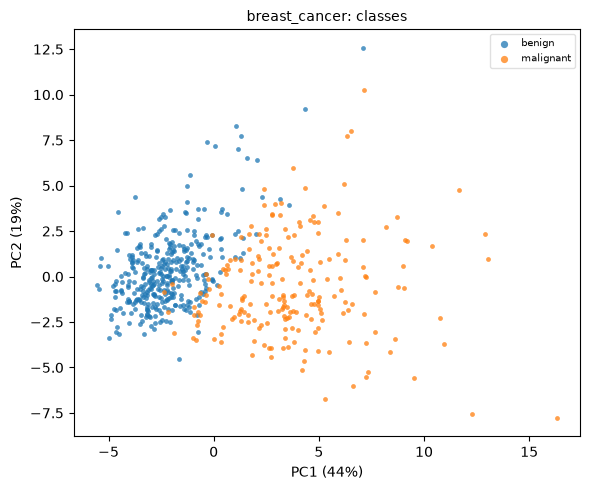

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/breast_cancer_data.png')

In [3]:
from sc4020.generate_figures import plot_coords, scatter_labels, show_and_save
x, y, x_label, y_label = plot_coords(ds)
fig, ax = plt.subplots(figsize=(6, 5))
scatter_labels(
    ax,
    np.column_stack([x, y]),
    ds.target,
    title=f"{DATASET_NAME}: {'classes' if ds.target is not None else 'points'}",
    class_names=ds.get("target_names"),
    size=2 if len(ds.data) > 5000 else 12,
)
ax.set_xlabel(x_label)
ax.set_ylabel(y_label)
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_data")

## 2. Clustering with K-Means

The number of clusters k comes from the fake-data check: for each k, the silhouette on the real data
minus the mean silhouette on copies with every column shuffled, among the k whose seeds agree. On
labelled data K-Means uses the true number of classes, and the label-free choice is shown next to it.
Plain K-Means starts from random centres; K-Means++ (next section) uses the same k.

In [4]:
selections, results = {}, {}
selections["K-Means"] = run.select_method(ds, "K-Means", k_range=k_range)
kmeans_tried = pd.DataFrame(selections["K-Means"].tried)
label_free_k = selections["K-Means"].label_free["n_clusters"]
print(f"k used: {selections['K-Means'].params['n_clusters']}, label-free choice: {label_free_k}")
kmeans_tried.round(3)

k used: 2, label-free choice: 2


,n_clusters,inertia,silhouette,null_silhouette,null_gap,davies_bouldin,smallest_cluster,largest_cluster,mean_seed_ari,min_seed_ari,ari
0,2,11595.527,0.343,0.031,0.312,1.321,194,375,0.981,0.965,0.654
1,3,10061.798,0.314,0.027,0.287,1.529,100,359,1.000,1.000,0.511
2,4,9258.989,0.283,0.026,0.258,1.489,35,345,0.728,0.428,0.552
3,5,8558.661,0.158,0.020,0.139,1.756,35,204,0.872,0.756,0.329
4,6,7970.264,0.160,0.020,0.141,1.720,20,205,0.885,0.732,0.332
5,7,7540.319,0.153,0.023,0.130,1.677,15,157,0.844,0.546,0.257
6,8,7254.326,0.147,0.024,0.124,1.618,18,147,0.675,0.407,0.226
7,9,6837.629,0.147,0.021,0.126,1.485,2,132,0.673,0.367,0.196
8,10,6603.404,0.137,0.020,0.117,1.607,2,141,0.646,0.478,0.201


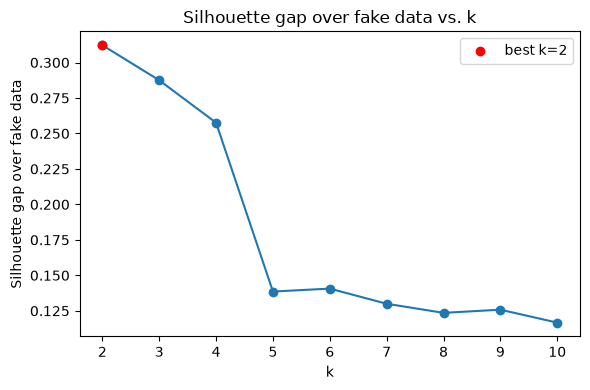

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/breast_cancer_kmeans_k_selection.png')

In [5]:
from sc4020.generate_figures import plot_k_selection, show_and_save
fig = plot_k_selection(
    kmeans_tried["n_clusters"].tolist(),
    kmeans_tried["null_gap"].tolist(),
    best_k=label_free_k,
    ylabel="Silhouette gap over fake data",
)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_kmeans_k_selection")

In [6]:
selections["K-Means (random init)"] = run.select_method(ds, "K-Means (random init)", selections)
results["K-Means (random init)"] = run.fit_method(
    ds, "K-Means (random init)", selections["K-Means (random init)"]
)

## 3. Clustering with K-Means++

In [7]:
results["K-Means"] = run.fit_method(ds, "K-Means", selections["K-Means"])
pd.DataFrame(
    {
        name: {
            "inertia": results[name].model.inertia_,
            "iterations": results[name].model.n_iter_,
            "fit_seconds": results[name].fit_seconds,
        }
        for name in ("K-Means (random init)", "K-Means")
    }
).T.round(3)

,inertia,iterations,fit_seconds
K-Means (random init),11595.527,8.0,1.023
K-Means,11595.527,7.0,1.202


## 4. Clustering with DBSCAN

min_samples follows the dimension, and eps is tried at multiples of the knee of the k-distance curve.
The rule keeps settings with at least 2 clusters and at most half the points as noise, then takes the
highest silhouette.

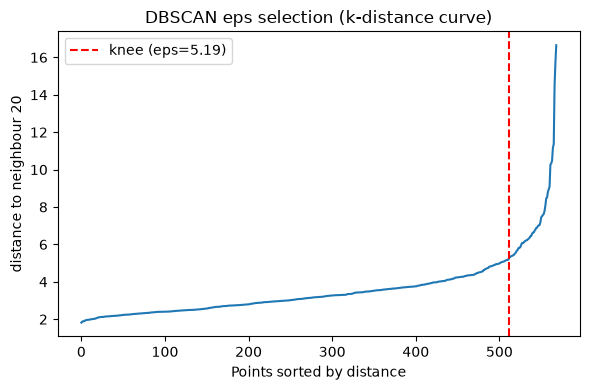

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/breast_cancer_dbscan_k_distance.png')

In [8]:
from sc4020.generate_figures import plot_k_distance, show_and_save
min_samples = tuning.min_samples_from_dimension(ds.data.shape[1])
curve = tuning.k_distance_curve(ds.data, min_samples)
knee_index, eps_at_knee = tuning.find_knee(curve)
fig = plot_k_distance(curve, knee_index, eps_at_knee, min_samples)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_dbscan_k_distance")

In [9]:
selections["DBSCAN"] = run.select_method(ds, "DBSCAN", max_clusters=MAX_CLUSTERS)
results["DBSCAN"] = run.fit_method(ds, "DBSCAN", selections["DBSCAN"])
print(f"chosen: {run.format_params(selections['DBSCAN'].params)}, rule satisfied: {selections['DBSCAN'].valid}")
pd.DataFrame(selections["DBSCAN"].tried).round(3)

chosen: eps=2.33, min_samples=10, rule satisfied: False


,eps,min_samples,eps_factor,n_clusters,noise_fraction,largest_cluster_share,silhouette,ari,passes
0,2.325,10,0.50,2,0.555,0.420,0.356,0.222,False
1,3.488,10,0.75,1,0.148,0.852,NaN,0.090,False
2,2.596,20,0.50,1,0.527,0.473,NaN,0.317,False
3,3.894,20,0.75,1,0.125,0.875,NaN,0.088,False
4,2.940,40,0.50,1,0.467,0.533,NaN,0.358,False
5,3.380,80,0.50,1,0.381,0.619,NaN,0.369,False


## 5. Clustering with HDBSCAN

In [10]:
selections["HDBSCAN"] = run.select_method(ds, "HDBSCAN", max_clusters=MAX_CLUSTERS)
results["HDBSCAN"] = run.fit_method(ds, "HDBSCAN", selections["HDBSCAN"])
print(f"chosen: {run.format_params(selections['HDBSCAN'].params)}, rule satisfied: {selections['HDBSCAN'].valid}")
pd.DataFrame(selections["HDBSCAN"].tried).round(3)

chosen: min_cluster_size=5, min_samples=None, rule satisfied: False


,min_cluster_size,min_samples,n_clusters,noise_fraction,largest_cluster_share,silhouette,ari,passes
0,5,NaN,2,0.592,0.385,0.364,0.156,False
1,5,5.0,2,0.592,0.385,0.364,0.156,False
2,5,10.0,2,0.615,0.374,0.358,0.167,False
3,10,NaN,0,1.000,0.000,NaN,0.000,False
4,10,5.0,2,0.592,0.385,0.364,0.156,False
5,10,10.0,0,1.000,0.000,NaN,0.000,False
6,15,NaN,0,1.000,0.000,NaN,0.000,False
7,15,5.0,0,1.000,0.000,NaN,0.000,False
8,15,10.0,0,1.000,0.000,NaN,0.000,False
9,20,NaN,0,1.000,0.000,NaN,0.000,False


## 6. Clustering with GMM

The number of components and the covariance type with the lowest BIC (the number of components is the
number of classes on labelled data).

In [11]:
selections["GMM"] = run.select_method(ds, "GMM", k_range=k_range)
results["GMM"] = run.fit_method(ds, "GMM", selections["GMM"])
gmm_tried = pd.DataFrame(selections["GMM"].tried).rename(columns={"score": "minus_bic"})
print(f"chosen: {run.format_params(selections['GMM'].params)}, label-free: {run.format_params(selections['GMM'].label_free)}")
gmm_tried.pivot(index="n_components", columns="covariance_type", values="minus_bic").round(1)

chosen: n_components=2, covariance_type=full, label-free: n_components=2, covariance_type=full


covariance_type,diag,full,spherical,tied
n_components,,,,
2,-37876.9,-6094.0,-40561.6,-11299.5
3,-35697.8,-6252.0,-38580.8,-11156.3
4,-33792.0,-6364.5,-36983.9,-10865.9
5,-32334.7,-7859.3,-35959.4,-10907.5
6,-31126.0,-7206.6,-35097.2,-10684.7
7,-30503.7,-9467.0,-34657.0,-10666.2
8,-29537.5,-9302.8,-33871.7,-9715.5
9,-29068.6,-10515.3,-33624.1,-9560.4
10,-28902.6,-12457.4,-33228.2,-9457.2


## 7. Clustering with Spectral, Agglomerative and Affinity Propagation

Spectral and Agglomerative (Ward) take the K-Means k; Affinity Propagation picks its own number of
exemplars. All three need memory quadratic in the number of points, so they are skipped on large data.

In [12]:
for name in ("Spectral", "Agglomerative", "Affinity Propagation"):
    if run.is_too_large(ds, name):
        print(f"skipping {name}: {len(ds.data):,} points is above {run.MAX_POINTS_FOR_QUADRATIC_METHODS:,}")
        continue
    selections[name] = run.select_method(ds, name, selections)
    results[name] = run.fit_method(ds, name, selections[name])
    print(f"{name}: {run.format_params(selections[name].params)}")

Spectral: n_clusters=2, affinity=nearest_neighbors
Agglomerative: n_clusters=2, linkage=ward


Affinity Propagation: damping=0.9, preference=-150


## 8. Metrics

Internal scores (silhouette, Davies-Bouldin, DBCV) need no labels; ARI and NMI compare with the classes
when there are any. Noise points are left out of the internal scores.

In [13]:
table = run.score_methods(ds, selections, results)
run.save_dataset_run(DATASET_NAME, table, run.tried_settings(ds, selections))
columns = ["method", "params", "n_clusters", "noise_fraction", "silhouette", "davies_bouldin", "dbcv", "ari", "nmi", "fit_seconds"]
table[[column for column in columns if column in table]].round(3)

,method,params,n_clusters,noise_fraction,silhouette,davies_bouldin,dbcv,ari,nmi,fit_seconds
0,K-Means (random init),n_clusters=2,2,0.000,0.343,1.321,-0.643,0.654,0.532,1.023
1,K-Means,n_clusters=2,2,0.000,0.343,1.321,-0.643,0.654,0.532,1.202
2,DBSCAN,"eps=2.33, min_samples=10",2,0.555,0.356,0.853,0.043,0.222,0.255,0.058
3,HDBSCAN,"min_cluster_size=5, min_samples=None",2,0.592,0.364,0.844,0.005,0.156,0.213,0.018
4,GMM,"n_components=2, covariance_type=full",2,0.000,0.314,1.377,-0.636,0.774,0.661,0.963
5,Spectral,"n_clusters=2, affinity=nearest_neighbors",2,0.000,0.337,1.316,-0.685,0.761,0.663,0.730
6,Agglomerative,"n_clusters=2, linkage=ward",2,0.000,0.339,1.370,-0.544,0.575,0.457,0.035
7,Affinity Propagation,"damping=0.9, preference=-150",16,0.000,0.094,1.566,-0.432,0.122,0.309,0.250


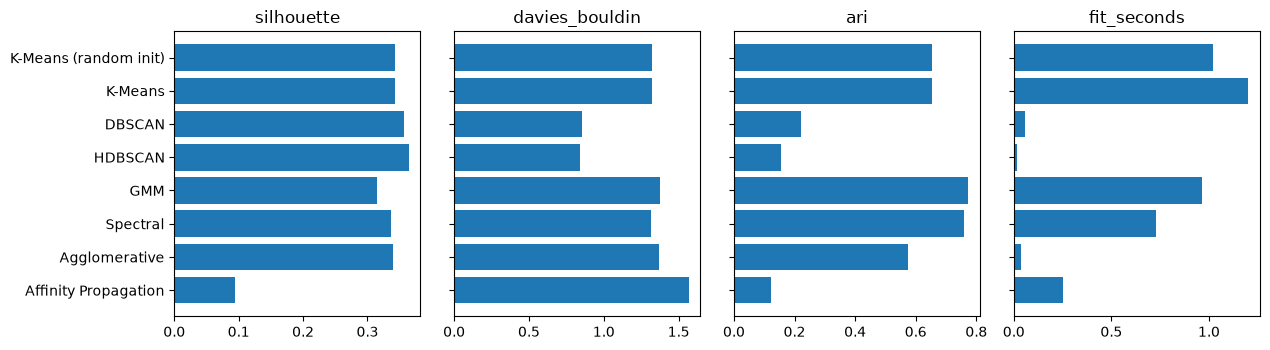

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/breast_cancer_metrics.png')

In [14]:
from sc4020.generate_figures import show_and_save
metric_names = [m for m in ("silhouette", "davies_bouldin", "ari", "fit_seconds") if m in table]
fig, axes = plt.subplots(1, len(metric_names), figsize=(3.2 * len(metric_names), 3.6), sharey=True)
for ax, metric in zip(axes, metric_names):
    ax.barh(table["method"], table[metric])
    ax.set_title(metric)
axes[0].invert_yaxis()
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_metrics")

### Report shared table

The report's shared columns for this dataset: the four tuned methods plus Agglomerative (Ward) and
Spectral (nearest-neighbour graph) at the number of classes, with the same selection and fit repeated on
fake data (every column shuffled). Written to `results/comparison/report_d6_d7.csv`.

In [15]:
shared_rows, shared_labels_by_method = run.shared_table_rows(ds)
run.save_shared_table_rows(shared_rows)
pd.DataFrame(shared_rows).drop(columns=["params"]).round(3)

,dataset,method,n_clusters,noise_fraction,largest_cluster_share,silhouette,davies_bouldin,calinski_harabasz,ari,nmi,ami,fmi,fit_seconds,null_silhouette,null_clusters,null_noise_fraction
0,breast_cancer,K-Means,2,0.000,0.659,0.343,1.321,267.692,0.654,0.532,0.532,0.841,0.386,0.033,2,0.000
1,breast_cancer,DBSCAN,2,0.555,0.420,0.356,0.853,46.676,0.222,0.255,0.253,0.617,0.028,NaN,1,0.167
2,breast_cancer,HDBSCAN,2,0.592,0.385,0.364,0.844,44.561,0.156,0.213,0.211,0.591,0.020,NaN,0,1.000
3,breast_cancer,GMM,2,0.000,0.624,0.314,1.377,247.284,0.774,0.661,0.661,0.894,0.918,0.032,2,0.000
4,breast_cancer,Agglomerative,2,0.000,0.677,0.339,1.370,248.629,0.575,0.457,0.456,0.807,0.008,0.018,2,0.000
5,breast_cancer,Spectral,2,0.000,0.670,0.337,1.316,259.663,0.761,0.663,0.662,0.891,0.483,0.023,2,0.000


## 9. Visualization

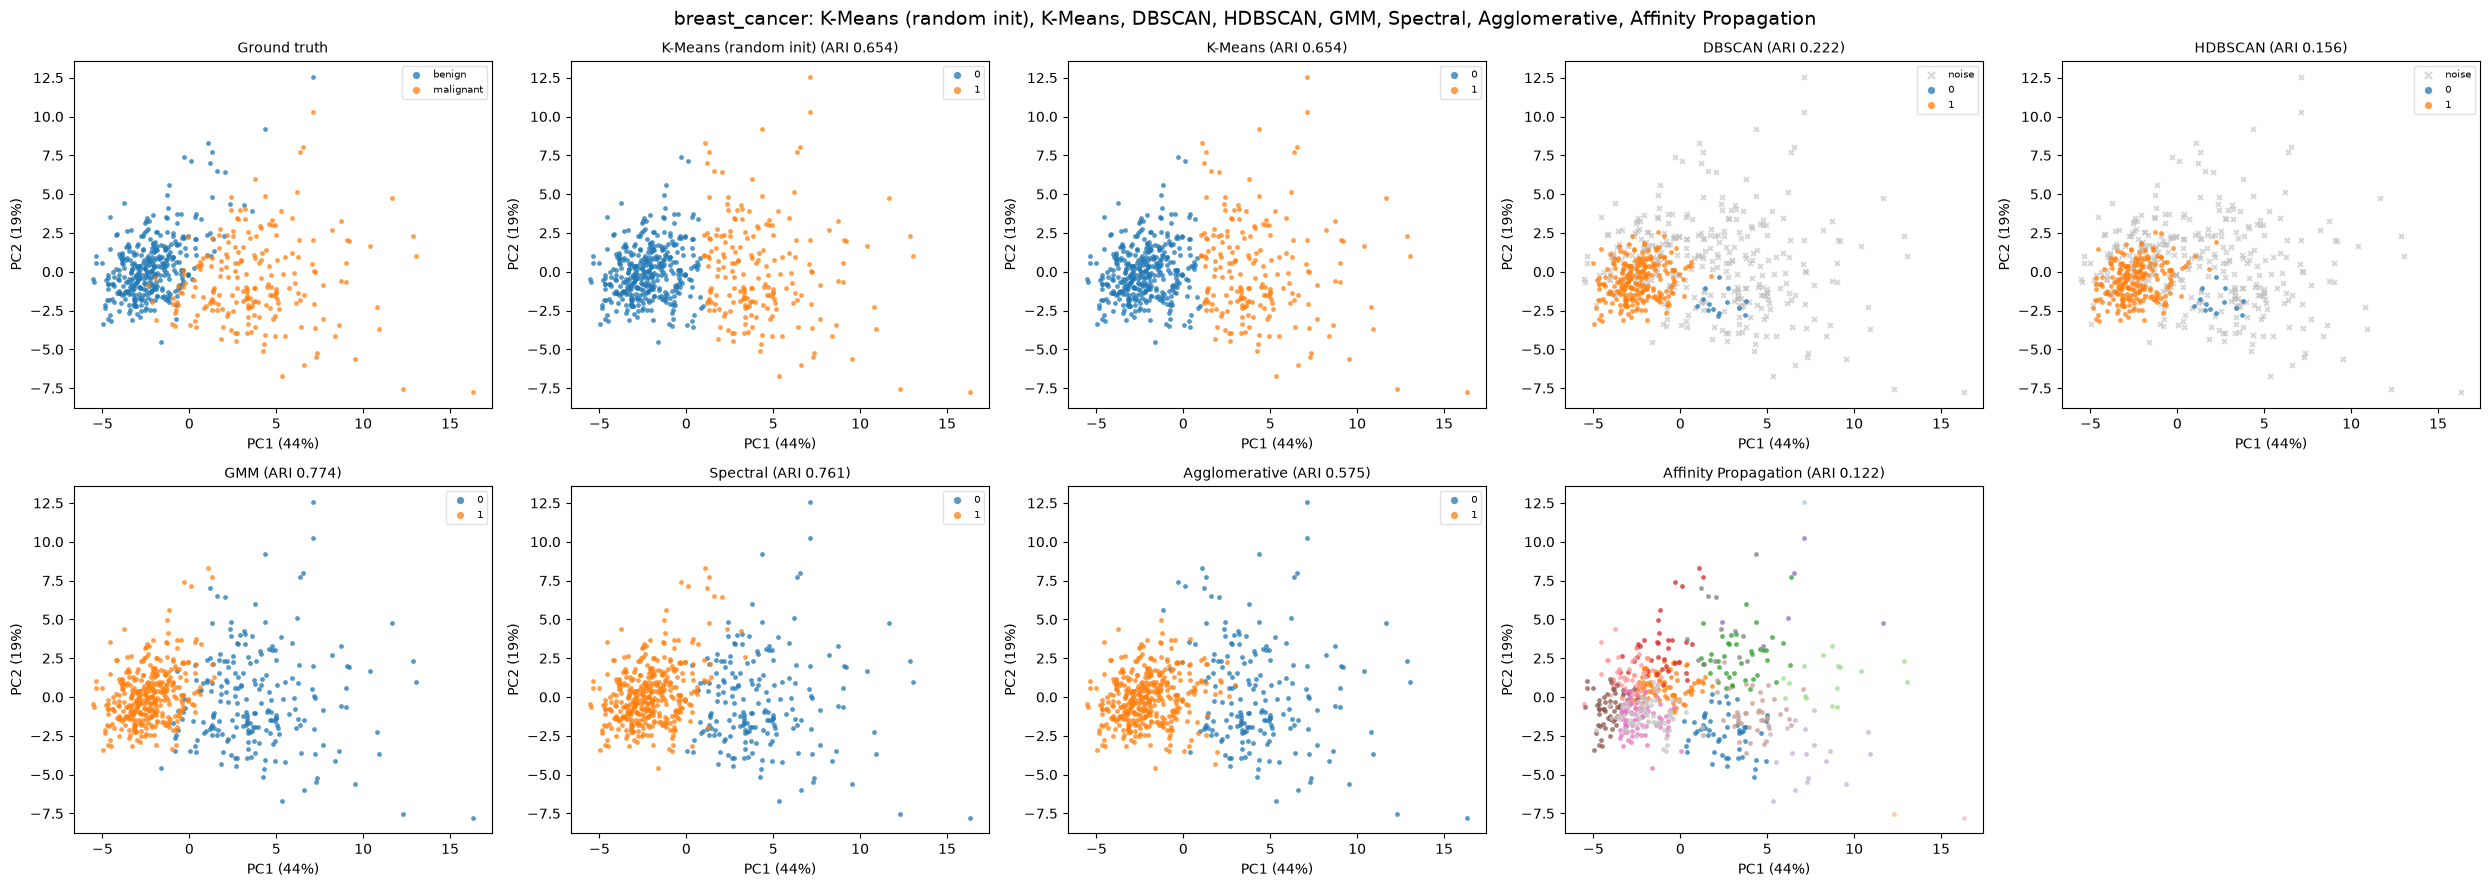

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/breast_cancer_clusters.png')

In [16]:
from sc4020.generate_figures import show_and_save
fig = run.plot_dataset(ds, results, table, title=f"{DATASET_NAME}: {', '.join(results)}")
show_and_save(fig, TOPIC, f"{DATASET_NAME}_clusters")

Success and failure cases for the report (`report/figures/bc_cases.png`).

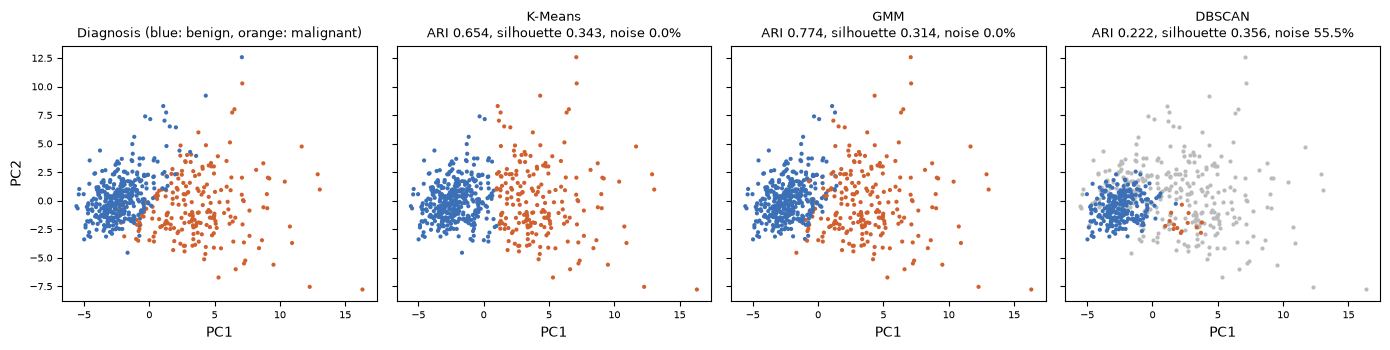

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/report/figures/bc_cases.png')

In [17]:
from sc4020.generate_figures import plot_case_figure, show_and_save_to
fig = plot_case_figure(
    ds.data, ds.target, shared_labels_by_method, shared_rows, picks=("K-Means", "GMM", "DBSCAN")
)
show_and_save_to(fig, REPORT_FIGURES_DIR / "bc_cases.png")